### Q4.1

In [1]:
import hashlib

# 1. Get the username part of your email
username = "ritama.sanyal"

# 2. Generate the saeed using the provided formula
your_seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)

print(f"Your personalized random seed is: {your_seed}")

Your personalized random seed is: 284869898


In [2]:
import numpy as np
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt
from PIL import Image

class GMM:
    """
    A Gaussian Mixture Model (GMM) implementation using the Expectation-Maximization (EM) algorithm.

    Attributes
    ----------
    k : int
        Number of Gaussian components (clusters).
    max_iter : int
        Maximum number of EM iterations.
    tol : float
        Convergence tolerance on log-likelihood improvement.
    reg_cov : float
        Regularization term added to covariance diagonals to prevent singularities.
    weights : ndarray
        Mixture weights of shape (k,).
    means : ndarray
        Mean vectors of shape (k, n_features).
    covs : ndarray
        Covariance matrices of shape (k, n_features, n_features).
    responsibilities : ndarray
        Posterior probabilities (membership values) of shape (n_samples, k).
    likelihood_history : list
        Stores log-likelihood values across EM iterations.
    """

    def __init__(self, k, max_iter=100, tol=1e-4, reg_cov=1e-6):
        """
        Initialize a GMM instance.

        Parameters
        ----------
        k : int
            Number of Gaussian components.
        max_iter : int, optional
            Maximum EM iterations (default: 100).
        tol : float, optional
            Convergence tolerance (default: 1e-4).
        reg_cov : float, optional
            Regularization added to covariance diagonals (default: 1e-6).
        """
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.reg_cov = reg_cov
        self.weights = None
        self.means = None
        self.covs = None
        self.likelihood_history = []
        self.responsibilities = None

    def _initialize_params(self, X):
        """Randomly initialize means, equal weights, and identity covariances."""
        n_samples, n_features = X.shape
        self.weights = np.full(self.k, 1/self.k)  # uniform weights
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.means = X[random_indices].astype(np.float64)  # random sample means
        self.covs = np.array([np.eye(n_features, dtype=np.float64) for _ in range(self.k)])

    def _e_step(self, X):
        """
        Expectation step: compute responsibilities (posterior probabilities).
        Updates self.responsibilities of shape (n_samples, k).
        """
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            # Regularize covariance for stability
            cov_reg = self.covs[i] + self.reg_cov * np.eye(self.covs[i].shape[0])
            distribution = multivariate_normal(mean=self.means[i], cov=cov_reg, allow_singular=True)
            likelihoods[:, i] = distribution.pdf(X)

        # Weight by mixture weights
        weighted_likelihoods = likelihoods * self.weights
        sum_of_likelihoods = np.sum(weighted_likelihoods, axis=1, keepdims=True)
        # Normalize to obtain responsibilities
        self.responsibilities = weighted_likelihoods / (sum_of_likelihoods + 1e-9)

    def _m_step(self, X):
        """
        Maximization step: update weights, means, and covariances based on responsibilities.
        """
        n_samples, n_features = X.shape
        Nk = np.sum(self.responsibilities, axis=0)  # effective cluster sizes

        # Update weights
        self.weights = Nk / n_samples
        # Update means
        self.means = (self.responsibilities.T @ X) / (Nk[:, np.newaxis] + 1e-9)

        # Update covariances for each cluster
        for i in range(self.k):
            diff = X - self.means[i]
            cov_i = (self.responsibilities[:, i, np.newaxis] * diff).T @ diff
            # Regularized covariance
            self.covs[i] = (cov_i / (Nk[i] + 1e-9)) + self.reg_cov * np.eye(n_features)

    def _calculate_log_likelihood(self, X):
        """
        Compute the log-likelihood of the dataset under the current model.
        """
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            cov_reg = self.covs[i] + self.reg_cov * np.eye(self.covs[i].shape[0])
            distribution = multivariate_normal(self.means[i], cov_reg, allow_singular=True)
            likelihoods[:, i] = distribution.pdf(X)
        weighted_likelihoods = likelihoods @ self.weights
        return np.sum(np.log(weighted_likelihoods + 1e-9))

    def fit(self, X):
        """
        Fit the GMM to the dataset using the EM algorithm.

        Parameters
        ----------
        X : ndarray
            Dataset of shape (n_samples, n_features).
        """
        self._initialize_params(X)
        for i in range(self.max_iter):
            try:
                self._e_step(X)
                self._m_step(X)
                log_likelihood = self._calculate_log_likelihood(X)
            except np.linalg.LinAlgError:
                print(f"Singular matrix error at iteration {i}. Stopping.")
                break

            self.likelihood_history.append(log_likelihood)

            # Convergence check
            if i > 0 and abs(log_likelihood - self.likelihood_history[-2]) < self.tol:
                print(f"Converged at iteration {i+1}")
                break
        print("Fitting complete.")

    def getMembership(self):
        """
        Get membership probabilities (responsibilities) for each sample.

        Returns
        -------
        responsibilities : ndarray
            Posterior probabilities of shape (n_samples, k).
        """
        if self.responsibilities is None:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.responsibilities

    def getLikelihood(self):
        """
        Get the final log-likelihood of the dataset.

        Returns
        -------
        float
            Final log-likelihood value.
        """
        if not self.likelihood_history:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.likelihood_history[-1]

    def drawLikelihood(self, username="ritama.sanyal"):
        """
        Plot the log-likelihood curve across EM iterations.

        Parameters
        ----------
        username : str, optional
            Watermark text to display on the plot (default: "ritama.sanyal").
        """
        if not self.likelihood_history:
            print("Likelihood history is empty. Call fit() first.")
            return
        plt.figure(figsize=(10,6))
        plt.text(0.95, 0.95, username, ha='right', va='top',
                 transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
        plt.plot(self.likelihood_history, marker='o')
        plt.title('Log-Likelihood vs. Iterations')
        plt.xlabel('Iteration')
        plt.ylabel('Log-Likelihood')
        plt.grid(True)
        plt.show()

    def predict(self, X):
        """
        Assign each sample to the cluster with the highest responsibility.

        Parameters
        ----------
        X : ndarray
            Dataset of shape (n_samples, n_features).

        Returns
        -------
        labels : ndarray
            Cluster labels of shape (n_samples,).
        """
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            cov_reg = self.covs[i] + self.reg_cov * np.eye(self.covs[i].shape[0])
            distribution = multivariate_normal(mean=self.means[i], cov=cov_reg, allow_singular=True)
            likelihoods[:, i] = distribution.pdf(X)
        weighted_likelihoods = likelihoods * self.weights
        resp = weighted_likelihoods / (np.sum(weighted_likelihoods, axis=1, keepdims=True) + 1e-9)
        return resp.argmax(axis=1)


Converged at iteration 88
Fitting complete.
labels unique: [0 1 2]
Saved segmented image to: segmented_satellite_1.png


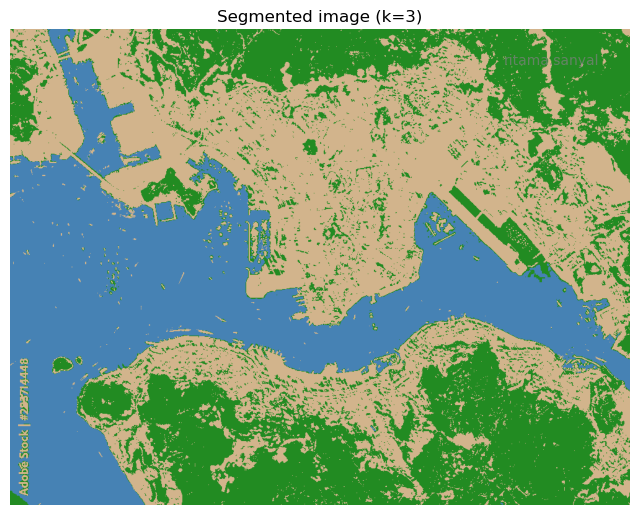

Fitting complete.
labels unique: [0 1 2]
Saved segmented image to: segmented_satellite_2.png


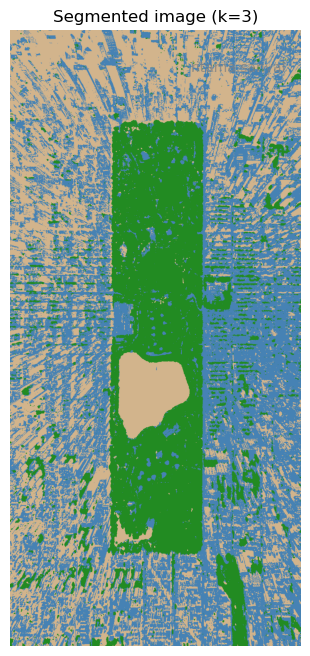

In [3]:
# ----------------------------
# Segmentation pipeline (run this cell after the GMM class)
# ----------------------------
def segment_image_with_gmm(image_path, out_path='segmented_satellite.png'):
    """
    Perform color-based image segmentation using a custom Gaussian Mixture Model (GMM).

    Parameters
    ----------
    image_path : str
        Path to the input satellite image (PNG, JPG, etc.).
    out_path : str, optional
        Path where the segmented image will be saved. Default: 'segmented_satellite.png'.

    Returns
    -------
    None
        The function saves the segmented image and also displays it inline.
    """

    # ----------------------------
    # Load and preprocess the image
    # ----------------------------
    img = Image.open(image_path).convert('RGB')   # Ensure RGB mode (ignore alpha if present)
    arr = np.array(img)                           # Convert to NumPy array (H, W, 3), dtype=uint8
    H, W, C = arr.shape                           # Dimensions of the image
    # Flatten image into (num_pixels, 3) for GMM fitting
    X = arr.reshape(-1, 3).astype(np.float64)

    # ----------------------------
    # Define a fixed color palette for 3 clusters
    # Each row corresponds to an RGB color
    # ----------------------------
    PALETTE = np.array([
        [34, 139, 34],   # vegetation (forest green)
        [210, 180, 140],  # water (steel blue)
        [70, 130, 180], # land/soil (tan)
    ], dtype=np.uint8)

    # ----------------------------
    # Fit the Gaussian Mixture Model (GMM) to image pixels
    # ----------------------------
    np.random.seed(0)  # Fix seed for reproducibility
    gmm = GMM(k=3, max_iter=100, tol=1e-4, reg_cov=1e-6)
    gmm.fit(X)

    # ----------------------------
    # Predict cluster labels for each pixel
    # ----------------------------
    labels = gmm.predict(X)               # Shape: (num_pixels,)
    labels = np.asarray(labels).astype(int).ravel()
    print("labels unique:", np.unique(labels))

    # ----------------------------
    # Map cluster labels -> colors using the fixed palette
    # Ensures consistent mapping even if labels are not in {0,1,2}
    # ----------------------------
    unique = np.unique(labels)
    label_to_idx = {lab: i % len(PALETTE) for i, lab in enumerate(unique)}
    mapped = np.vectorize(label_to_idx.get)(labels)  # Map labels to palette indices
    seg_flat = PALETTE[mapped]                       # Replace label with corresponding RGB color
    seg_img = seg_flat.reshape(H, W, 3).astype(np.uint8)

    # ----------------------------
    # Save and display the segmented image
    # ----------------------------
    Image.fromarray(seg_img).save(out_path)
    print("Saved segmented image to:", out_path)

    plt.figure(figsize=(8,8))
    plt.imshow(seg_img)
    # Add watermark/username on top-right corner
    plt.text(0.95, 0.95, "ritama.sanyal", ha='right', va='top', 
             transform=plt.gca().transAxes, fontsize=10, color='gray', alpha=0.7)
    plt.axis('off')
    plt.title('Segmented image (k=3)')
    plt.show()


# ----------------------------
# Example usage: segment both satellite images
# ----------------------------
segment_image_with_gmm('satellite_1.png', out_path='segmented_satellite_1.png')
segment_image_with_gmm('satellite_2.png', out_path='segmented_satellite_2.png')


### Q4.2

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import imageio

# --- Fixed palette (RGB) ---
PALETTE = np.array([
    [34, 139, 34],   # vegetation  (forest green)
    [70, 130, 180],  # water       (steel blue)
    [210, 180, 140], # land/soil   (tan)
], dtype=np.uint8)

def gmm_fit_with_history(gmm, X, max_iter=20):
    """
    Fit a GMM while recording labels, means, and log-likelihood per iteration.

    Parameters
    ----------
    gmm : object
        Your GMM instance exposing _initialize_params, _e_step, _m_step,
        _calculate_log_likelihood, and attributes .responsibilities, .means, .tol.
    X : (N, D) ndarray
        Data matrix (pixels flattened to RGB vectors).
    max_iter : int
        Maximum EM iterations for history recording (the GMM may stop earlier).

    Returns
    -------
    labels_history : list[np.ndarray]
        argmax responsibility labels at each iteration, shape (N,) per item.
    means_history : list[np.ndarray]
        Cluster means at each iteration, shape (K, D) per item.
    loglik_history : list[float]
        Log-likelihood values per iteration.
    """
    gmm._initialize_params(X)
    labels_history, means_history, loglik_history = [], [], []

    for i in range(max_iter):
        gmm._e_step(X)
        gmm._m_step(X)
        ll = gmm._calculate_log_likelihood(X)

        labels = gmm.responsibilities.argmax(axis=1)
        labels_history.append(labels.copy())
        means_history.append(gmm.means.copy())
        loglik_history.append(ll)

        # simple convergence check on log-likelihood
        if i > 0 and abs(ll - loglik_history[-2]) < gmm.tol:
            break

    return labels_history, means_history, loglik_history

def _labels_to_palette_image(labels, palette, H, W):
    """
    Convert integer cluster labels into an RGB image using a fixed palette.

    Assumes labels are in [0, K-1] and len(palette) == K.
    """
    seg = palette[labels]             # (H*W, 3)
    seg = seg.reshape(H, W, 3)        # (H, W, 3)
    return seg.astype(np.uint8)

def _compute_palette_assignment(means, palette):
    """
    Compute a label->palette index map by nearest color in RGB space.

    Parameters
    ----------
    means : (K, 3) ndarray
        Cluster means (in RGB space).
    palette : (K, 3) ndarray
        Fixed RGB palette.

    Returns
    -------
    assign : (K,) ndarray of ints
        For each cluster k, assign[k] = palette index to use.
    """
    # Pairwise squared distances between means and palette colors
    d2 = ((means[:, None, :] - palette[None, :, :]) ** 2).sum(axis=2)  # (K, K)

    # Greedy nearest (works fine for K=3). If you prefer optimal matching,
    # swap this for scipy.optimize.linear_sum_assignment.
    K = means.shape[0]
    assign = -np.ones(K, dtype=int)
    used_palette = set()
    for _ in range(K):
        i, j = divmod(d2.argmin(), d2.shape[1])
        while j in used_palette:
            d2[i, j] = np.inf
            i, j = divmod(d2.argmin(), d2.shape[1])
        assign[i] = j
        used_palette.add(j)
        d2[i, :] = np.inf  # lock this row
        d2[:, j] = np.inf  # lock this column
    return assign

def make_frame(orig_img, labels, means, loglik_history, iteration,
               palette=PALETTE, map_by_nearest=True, stable_colors=True):
    """
    Build a 3-panel frame with: (1) original, (2) segmentation (fixed palette),
    (3) log-likelihood curve. Adds a username watermark bottom-right.

    Parameters
    ----------
    orig_img : (H, W, 3) uint8
        Original RGB image.
    labels : (H*W,) int
        Cluster labels for each pixel.
    means : (K, 3) float
        Current cluster means (RGB).
    loglik_history : list[float]
        Log-likelihood values up to this iteration.
    iteration : int
        Current iteration index (1-based, for display if needed).
    palette : (K, 3) uint8
        Fixed RGB palette used to color clusters.
    map_by_nearest : bool
        If True, map each cluster index to the visually closest palette color.
        If False, use direct palette[labels] (i.e., label 0 → palette[0], etc.).
    stable_colors : bool
        If True, use mapping computed from **current** means each frame
        (keeps colors semantically aligned to cluster color).
        If False, use a fixed static mapping (label index = palette index).

    Returns
    -------
    frame : (H, W', 3) uint8
        The composed frame (concatenated panels).
    """
    H, W, C = orig_img.shape
    K = means.shape[0]
    assert K == len(palette), "Palette size must equal number of clusters (K)."

    # === Panel 1: original ===
    panel1 = orig_img

    # === Panel 2: segmentation using fixed palette ===
    if map_by_nearest and stable_colors:
        # Compute a mapping from cluster-id -> palette-id via nearest color
        assign = _compute_palette_assignment(means, palette)  # (K,)
        color_table = palette[assign]                         # (K, 3)
        seg = color_table[labels].reshape(H, W, C).astype(np.uint8)
    elif map_by_nearest and not stable_colors:
        # Compute a single mapping once outside and pass as palette; otherwise
        # this branch behaves like direct mapping. Left for completeness.
        seg = palette[labels].reshape(H, W, C).astype(np.uint8)
    else:
        # Direct mapping: label k -> palette[k]
        seg = palette[labels].reshape(H, W, C).astype(np.uint8)

    panel2 = seg

    # === Panel 3: log-likelihood curve ===
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.plot(range(1, len(loglik_history) + 1), loglik_history, marker='o')
    ax.set_title("Log-Likelihood")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Log-Likelihood")
    ax.grid(True)
    fig.canvas.draw()
    panel3 = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
    panel3 = panel3.reshape(fig.canvas.get_width_height()[::-1] + (3,))
    plt.close(fig)

    # === Concatenate panels horizontally (resize to same height) ===
    max_h = max(panel1.shape[0], panel2.shape[0], panel3.shape[0])
    panels = [panel1, panel2, panel3]
    panels_resized = []
    for p in panels:
        if p.shape[0] != max_h:
            scale = max_h / p.shape[0]
            new_w = int(p.shape[1] * scale)
            p = np.array(Image.fromarray(p).resize((new_w, max_h)))
        panels_resized.append(p)

    frame = np.hstack(panels_resized)

    # === Watermark ===
    pil_frame = Image.fromarray(frame)
    draw = ImageDraw.Draw(pil_frame)
    font = ImageFont.load_default()
    text = "ritama.sanyal"
    bbox = draw.textbbox((0, 0), text, font=font)
    text_w, text_h = bbox[2] - bbox[0], bbox[3] - bbox[1]
    x, y = pil_frame.width - text_w - 10, pil_frame.height - text_h - 10
    # Drop shadow for contrast
    draw.text((x+1, y+1), text, font=font, fill=(0, 0, 0))
    draw.text((x, y), text, font=font, fill=(255, 255, 255))

    return np.array(pil_frame)

def create_video(image_path, out_path="gmm_video.gif", max_iter=20, k=3,
                 palette=PALETTE, map_by_nearest=True):
    """
    Run GMM on the image and create an animation:
    Left = original, Middle = fixed-palette segmentation, Right = log-likelihood.

    Parameters
    ----------
    image_path : str
        Path to input image.
    out_path : str
        Output path (*.gif or *.mp4).
    max_iter : int
        Maximum iterations to record.
    k : int
        Number of clusters for the GMM; must match len(palette).
    palette : (k, 3) ndarray
        Fixed RGB palette to colorize clusters.
    map_by_nearest : bool
        If True, match cluster means to the closest palette color each frame.

    Returns
    -------
    None (saves the video to out_path)
    """
    # Load image
    img = Image.open(image_path).convert("RGB")
    orig_img = np.array(img)
    H, W, C = orig_img.shape
    X = orig_img.reshape(-1, 3).astype(np.float64)

    # Fit GMM and collect history
    gmm = GMM(k=k, max_iter=max_iter, tol=1e-4, reg_cov=1e-6)
    labels_hist, means_hist, loglik_hist = gmm_fit_with_history(gmm, X, max_iter=max_iter)

    # Build frames
    frames = []
    for it, (labels, means) in enumerate(zip(labels_hist, means_hist), start=1):
        frame = make_frame(
            orig_img,
            labels,
            means,
            loglik_hist[:it],
            iteration=it,
            palette=palette,
            map_by_nearest=map_by_nearest,
            stable_colors=True
        )
        frames.append(frame)

    # Save animation (GIF recommended for quick previews)
    imageio.mimsave(out_path, frames, fps=2)
    print(f"Saved video to {out_path}")


In [5]:
create_video("satellite_1.png", out_path="satellite1_gmm.gif", max_iter=30)
create_video("satellite_2.png", out_path="satellite2_gmm.gif", max_iter=30)


C:\Users\Ritama\AppData\Local\Temp\ipykernel_15604\955354676.py:164: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed two minor releases later. Use buffer_rgba instead.
  panel3 = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)


Saved video to satellite1_gmm.gif
Saved video to satellite2_gmm.gif


https://chatgpt.com/share/68c185ab-d380-800c-9a32-0d23adb3301e

https://iiithydresearch-my.sharepoint.com/:f:/g/personal/ritama_sanyal_research_iiit_ac_in/EjIXYVVWhJpHunjdaSCwCHgBrW4k0SXDdqrvW8N5xHK4Pg?e=uuLtVN